# CUDA SGEMM Optimization - run on Colab / Kaggle
1. **Runtime → Change runtime type → T4 GPU** (Kaggle: Settings → Accelerator → GPU T4).
2. Run the cells top to bottom. Results land in `results/`.


In [1]:
!nvidia-smi
!nvcc --version | tail -2
!which ncu || echo 'ncu not on PATH'

Tue Oct 13 00:08:47 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Get the code
Option A: clone your GitHub repo (edit the URL). Option B: upload the project zip.

In [2]:
REPO_URL = "https://github.com/Shubham19-bit/cuda-gemm-optimization.git"  # <- edit
import os
if not os.path.exists('cuda-gemm-optimization'):
    if '<your-username>' not in REPO_URL:
        !git clone $REPO_URL
    else:
        from google.colab import files  # Colab only; on Kaggle add the zip as a dataset
        up = files.upload()             # choose cuda-gemm-optimization.zip
        !unzip -q -o cuda-gemm-optimization.zip
%cd cuda-gemm-optimization
!git pull 2>/dev/null || true

Cloning into 'cuda-gemm-optimization'...
remote: Enumerating objects: 40, done.
remote: Counting objects: 100% (40/40), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 40 (delta 7), reused 40 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (40/40), 33.05 KiB | 4.72 MiB/s, done.
Resolving deltas: 100% (7/7), done.
/content/cuda-gemm-optimization
Already up to date.


## Build
`ARCH=sm_75` is the T4. On Kaggle P100 use `ARCH=sm_60` (no tensor cores: run without kernels 8/9).

In [3]:
!test -f Makefile || cp build.mk Makefile   # Makefile ships as build.mk in some copies
!make ARCH=sm_75
!grep -E 'Function properties|registers' results_ptxas.txt | head -40

nvcc -O3 -std=c++17 -arch=sm_75 -lineinfo -Xptxas -v src/main.cu -o gemm -lcublas 2> results_ptxas.txt || (cat results_ptxas.txt; exit 1)
Built ./gemm  (register/smem usage per kernel: results_ptxas.txt)
ptxas info    : Function properties for _Z20mygemm_k6_vectorizedILi128ELi128ELi8ELi8ELi8EEviiiPKfS1_Pf
ptxas info    : Used 125 registers, used 1 barriers, 8192 bytes smem, 392 bytes cmem[0]
ptxas info    : Function properties for _Z21mygemm_k5_blocktile2dILi128ELi128ELi8ELi8ELi8EEviiiPKfS1_Pf
ptxas info    : Used 127 registers, used 1 barriers, 8192 bytes smem, 392 bytes cmem[0]
ptxas info    : Function properties for _Z21mygemm_k4_blocktile1dILi64ELi64ELi8ELi8EEviiiPKfS1_Pf
ptxas info    : Used 64 registers, used 1 barriers, 4096 bytes smem, 392 bytes cmem[0]
ptxas info    : Function properties for _Z14mygemm_k3_smemILi32EEviiiPKfS1_Pf
ptxas info    : Used 42 registers, used 1 barriers, 8192 bytes smem, 392 bytes cmem[0]
ptxas info    : Function properties for _Z14mygemm_k8_wmmaiiiPK

## Optional: CPU-emulator self-check (no GPU needed)

In [4]:
!make test-emu | tail -25

Device: CPU emulator (no GPU) | SMs: 0 | compute capability 0.0
reps=1 warmup=0 check=on

id  kernel                       MxNxK     time_ms     GFLOPS   %cuBLAS    max_err  status
0   cublas_fp32            128x128x128      2.9328        1.4     93.1%   0.00e+00  ok
1   k1_naive               128x128x128    557.0208        0.0      0.5%   5.62e-07  ok
2   k2_coalesced           128x128x128    699.6227        0.0      0.4%   5.62e-07  ok
3   k3_smem_tiling         128x128x128   1160.1456        0.0      0.2%   5.62e-07  ok
4   k4_blocktile_1d        128x128x128    198.8049        0.0      1.4%   5.62e-07  ok
5   k5_blocktile_2d        128x128x128     23.9595        0.2     11.4%   5.62e-07  ok
6   k6_vectorized          128x128x128     23.8404        0.2     11.5%   5.62e-07  ok
8   k8_wmma_fp16           128x128x128     43.4632        0.1      6.3%   2.40e-04  ok
9   cublas_fp16_tc         128x128x128      2.8512        1.5     95.8%   2.40e-04  ok

0   cublas_fp32            256x256x

## Run all kernels
K1 at 4096 takes a few seconds per launch; total runtime is a few minutes.

In [5]:
!./gemm --kernel all --sizes 128 256 512 1024 2048 4096 --reps 10 --csv results/results.csv

Device: Tesla T4 | SMs: 40 | compute capability 7.5
reps=10 warmup=3 check=on

id  kernel                       MxNxK     time_ms     GFLOPS   %cuBLAS    max_err  status
0   cublas_fp32            128x128x128      0.0180      232.8    101.4%   0.00e+00  ok
1   k1_naive               128x128x128      0.1533       27.4     11.9%   5.00e-07  ok
2   k2_coalesced           128x128x128      0.0261      160.6     70.0%   5.00e-07  ok
3   k3_smem_tiling         128x128x128      0.0200      209.4     91.2%   5.00e-07  ok
4   k4_blocktile_1d        128x128x128      0.0315      133.1     58.0%   5.00e-07  ok
5   k5_blocktile_2d        128x128x128      0.0792       53.0     23.1%   5.00e-07  ok
6   k6_vectorized          128x128x128      0.0627       66.9     29.1%   5.00e-07  ok
8   k8_wmma_fp16           128x128x128      0.0102      412.2    179.6%   2.40e-04  ok
9   cublas_fp16_tc         128x128x128      0.0159      263.2    114.7%   2.40e-04  ok

0   cublas_fp32            256x256x256      0.

## Plots

Results at 4096x4096x4096

| Kernel | GFLOPS | % cuBLAS FP32 | Speedup vs K1 | max err |
|---|---|---|---|---|
| 0: cublas_fp32 | 4291.4 | 101.0% | 69.5x | 0.0e+00 |
| 1: k1_naive | 61.7 | 1.5% | 1.0x | 0.0e+00 |
| 2: k2_coalesced | 570.7 | 13.4% | 9.2x | 0.0e+00 |
| 3: k3_smem_tiling | 861.2 | 20.3% | 13.9x | 0.0e+00 |
| 4: k4_blocktile_1d | 1803.8 | 42.5% | 29.2x | 0.0e+00 |
| 5: k5_blocktile_2d | 3339.4 | 78.6% | 54.1x | 0.0e+00 |
| 6: k6_vectorized | 3483.5 | 82.0% | 56.4x | 0.0e+00 |
| 8: k8_wmma_fp16 | 1677.0 | 39.5% | 27.2x | 2.7e-04 |
| 9: cublas_fp16_tc | 32538.9 | 765.9% | 527.0x | 2.7e-04 |

Plots written to /content/cuda-gemm-optimization/results


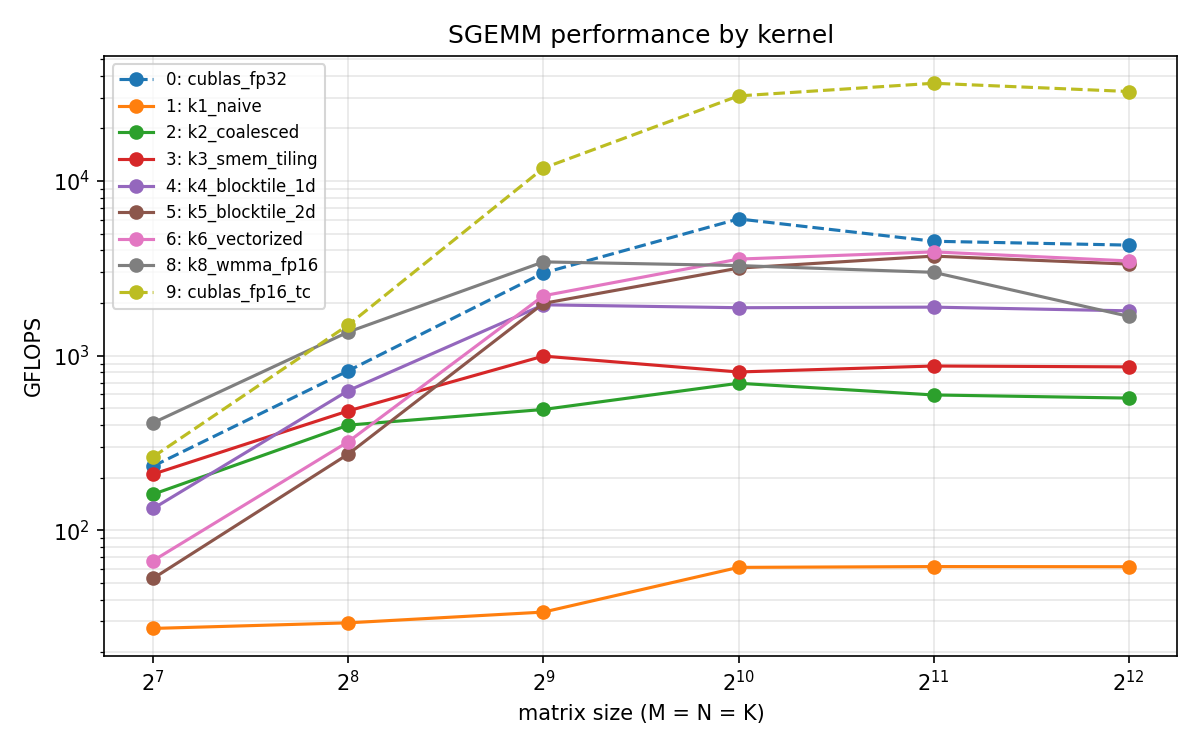

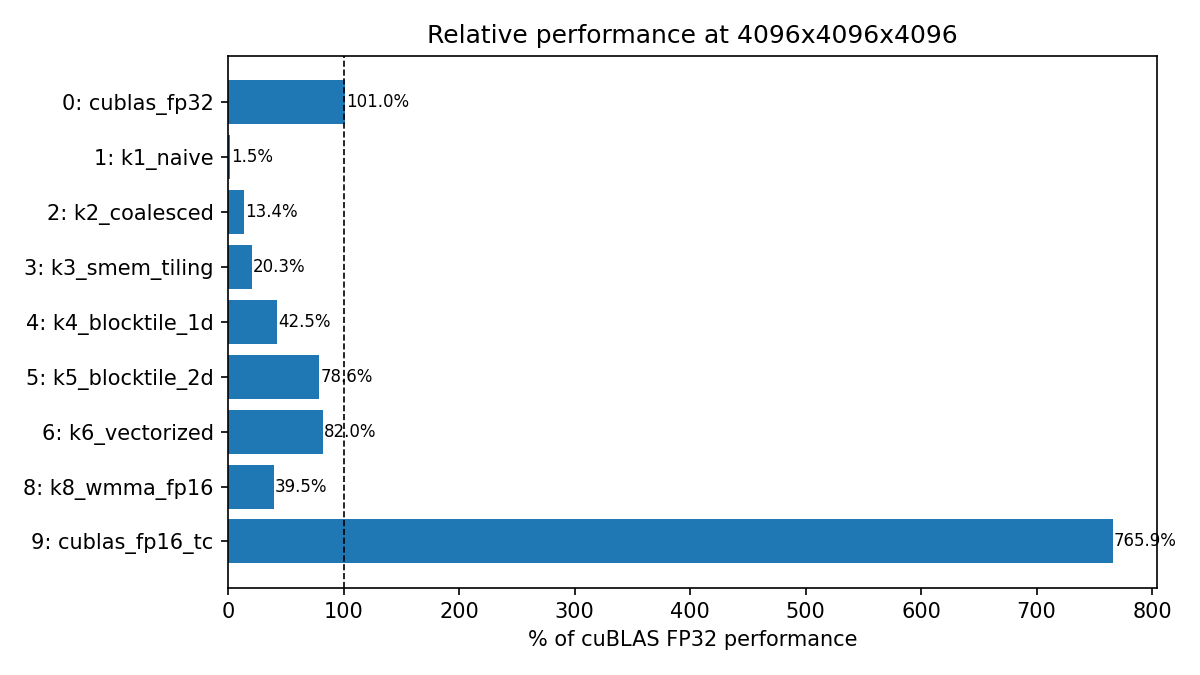

In [6]:
!python scripts/plot_perf.py results/results.csv
from IPython.display import Image, display
display(Image('results/perf_vs_size.png')); display(Image('results/pct_cublas.png'))

## Nsight Compute profiling
If you get `ERR_NVGPUCTRPERM`, counters are blocked on this platform - try Kaggle, or skip this step.

In [7]:
!bash scripts/profile_all.sh

>>> profiling kernel 1 at 4096^3
>>> profiling kernel 2 at 4096^3
>>> profiling kernel 3 at 4096^3
>>> profiling kernel 4 at 4096^3
>>> profiling kernel 5 at 4096^3
>>> profiling kernel 6 at 4096^3
>>> profiling kernel 8 at 4096^3
| id | GFLOPS | DRAM GB | FLOP/B | DRAM % | SM % | occupancy % | regs | smem ld/st conflicts |
|---|---|---|---|---|---|---|---|---|
| 1 | 22.7 | 17.89 | 7.7 | 0.9 | 6.0 | 98.1 | 52 | 0 / 0 |
| 2 | 322.3 | 13.27 | 10.4 | 9.7 | 86.1 | 98.6 | 52 | 0 / 0 |
| 3 | 411.9 | 13.25 | 10.4 | 12.4 | 75.7 | 100.0 | 42 | 0 / 0 |
| 4 | 962.4 | 6.54 | 21.0 | 14.3 | 58.3 | 99.6 | 64 | 0 / 0 |
| 5 | 1935.6 | 3.13 | 43.9 | 13.8 | 65.6 | 49.2 | 127 | 268435456 / 0 |
| 6 | 1933.3 | 2.35 | 58.6 | 10.3 | 64.5 | 49.3 | 125 | 268435456 / 16777216 |
| 8 | 1404.1 | 25.50 | 5.4 | 81.5 | 17.6 | 96.8 | 64 | 0 / 0 |


## Roofline

Roofline written to /content/cuda-gemm-optimization/results/roofline.png


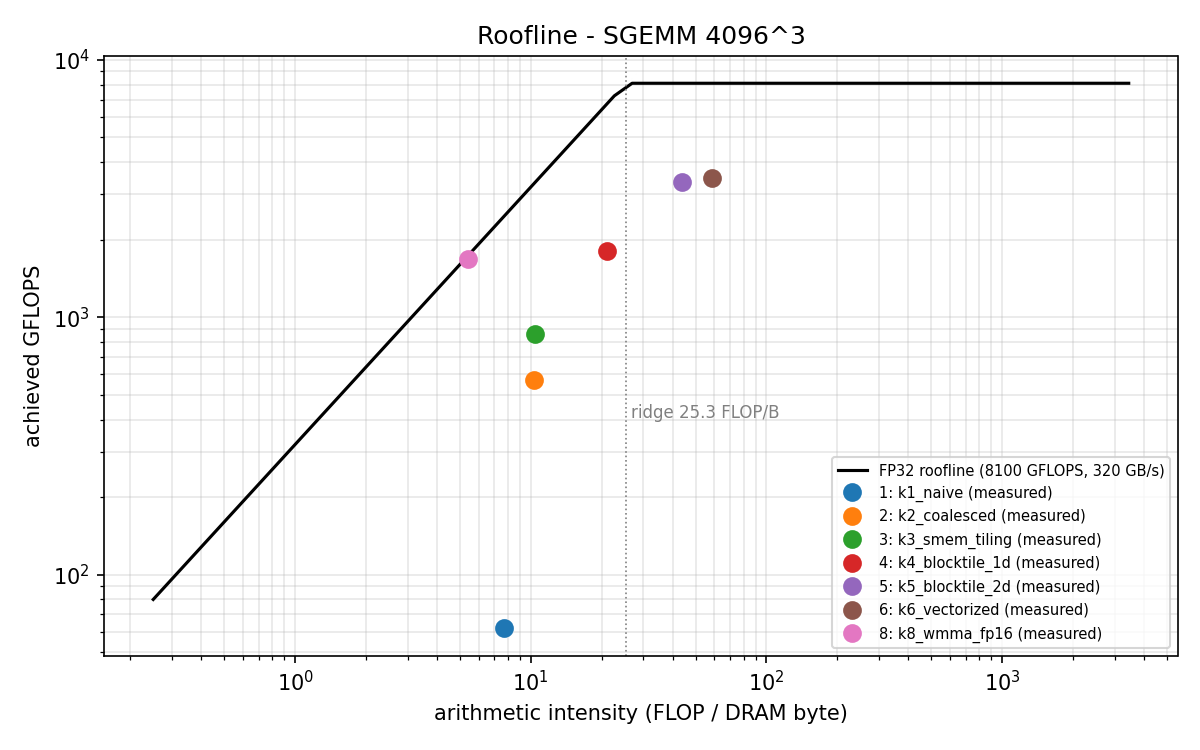

In [8]:
!python scripts/roofline.py --results results/results.csv --size 4096
display(Image('results/roofline.png'))

## Save results
Download the zip, or `git add results && git commit && git push` if you cloned with credentials.

In [9]:
!zip -q -r results.zip results results_ptxas.txt
try:
    from google.colab import files; files.download('results.zip')
except ImportError:
    print('On Kaggle: results.zip is in /kaggle/working - download it from the Output panel')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>